# Classification

# Cell 1: imports, load, MLflow setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib, mlflow, mlflow.sklearn
import warnings; warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

# MLflow: a SQLite backend is needed for the Model Registry
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("Good_Investment_Classification")

df = pd.read_csv("../data/processed_housing.csv")
df.shape

2026/10/31 18:54:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/31 18:54:12 INFO mlflow.store.db.utils: Updating database tables
2026/10/31 18:55:55 INFO mlflow.tracking.fluent: Experiment with name 'Good_Investment_Classification' does not exist. Creating a new experiment.


(250000, 43)

# Cell 2: features, target and split

In [2]:
num_features = ["BHK","Size_in_SqFt","Price_in_Lakhs","Price_per_SqFt_calc","Age_of_Property",
                "Floor_No","Total_Floors","Nearby_Schools","Nearby_Hospitals","Parking_Count",
                "Amenities_Count","Transport_Score","School_Density_Score","Hospital_Score",
                "Infrastructure_Score","Floor_Ratio","SqFt_per_BHK"]

cat_features = ["State","City","Property_Type","Furnished_Status","Public_Transport_Accessibility",
                "Security","Availability_Status","Facing","Owner_Type"]

TARGET = "Good_Investment"
X = df[num_features + cat_features]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))

(200000, 26) (50000, 26)
Good_Investment
1    0.536
0    0.464
Name: proportion, dtype: float64


# Cell 3: preprocessing pipeline

In [3]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

# Cell 4: helper that trains, evaluates and logs to MLflow

In [15]:
TRUSTED = ["sklearn.tree._tree.Tree", "xgboost.sklearn.XGBClassifier"]  # use the exact name from the error

def run_experiment(run_name, model, params, X_tr, X_te, y_tr, y_te, num_cols, cat_cols):
    pre = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    pipe = Pipeline([("prep", pre), ("model", model)])

    with mlflow.start_run(run_name=run_name) as run:
        pipe.fit(X_tr, y_tr)
        pred  = pipe.predict(X_te)
        proba = pipe.predict_proba(X_te)[:, 1]

        metrics = {
            "accuracy":  accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred),
            "recall":    recall_score(y_te, pred),
            "f1":        f1_score(y_te, pred),
            "roc_auc":   roc_auc_score(y_te, proba),
        }

        mlflow.log_params(params)
        mlflow.log_param("n_features_num", len(num_cols))
        mlflow.log_param("n_features_cat", len(cat_cols))
        mlflow.log_metrics(metrics)

        fig, ax = plt.subplots(figsize=(4, 4))
        ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                               display_labels=["Not Good", "Good"]).plot(ax=ax, colorbar=False)
        ax.set_title(run_name)
        mlflow.log_figure(fig, "confusion_matrix.png")
        plt.close(fig)

        info = mlflow.sklearn.log_model(pipe, name="model", serialization_format="cloudpickle")
        print(f"{run_name:32s}", {k: round(v, 4) for k, v in metrics.items()})
        return {"run_name": run_name, "run_id": run.info.run_id,
                "model_uri": info.model_uri, **metrics}, pipe

In [16]:
# 1) Trust only the types we need (we trained these models ourselves)
TRUSTED = ["sklearn.tree._tree.Tree", "xgboost.core.Booster", "xgboost.sklearn.XGBClassifier"]
print("TRUSTED =", TRUSTED)          # must show xgboost.core.Booster

# 2) Train + log XGBoost only
m, p = models["XGBoost"]
r, pipe = run_experiment("clf_XGBoost_all_features", m, p,
                         X_train, X_test, y_train, y_test, num_features, cat_features)
results.append(r)
pipes["XGBoost"] = pipe

print("Models trained so far:", list(pipes.keys()))

TRUSTED = ['sklearn.tree._tree.Tree', 'xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier']


2026/10/31 19:28:33 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


clf_XGBoost_all_features         {'accuracy': 0.9983, 'precision': 0.9984, 'recall': 0.9983, 'f1': 0.9984, 'roc_auc': 1.0}
Models trained so far: ['XGBoost']


# Cell 5: train the three models from the brief

In [17]:
results, pipes = [], {}

models = {
    "LogisticRegression": (LogisticRegression(max_iter=1000, random_state=42),
                           {"model": "LogisticRegression", "max_iter": 1000}),
    "RandomForest":       (RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
                           {"model": "RandomForest", "n_estimators": 100, "max_depth": 12}),
    "XGBoost":            (XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                         eval_metric="logloss", n_jobs=-1, random_state=42),
                           {"model": "XGBoost", "n_estimators": 200, "max_depth": 6, "learning_rate": 0.1}),
}

for name, (m, p) in models.items():
    m, p = models["XGBoost"]
r, pipe = run_experiment("clf_XGBoost_all_features", m, p,
                         X_train, X_test, y_train, y_test, num_features, cat_features)
results.append(r); pipes["XGBoost"] = pipe

print("Models trained so far:", list(pipes.keys()))

2026/10/31 19:28:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


clf_XGBoost_all_features         {'accuracy': 0.9983, 'precision': 0.9984, 'recall': 0.9983, 'f1': 0.9984, 'roc_auc': 1.0}
Models trained so far: ['XGBoost']


In [18]:
print(list(pipes.keys()))   # expect ['LogisticRegression', 'RandomForest', 'XGBoost']
print(len(results))         # expect 3

['XGBoost']
1


In [23]:
TRUSTED = ["sklearn.tree._tree.Tree", "xgboost.core.Booster", "xgboost.sklearn.XGBClassifier"]

done = [r["run_name"] for r in results]
for name in ["LogisticRegression", "RandomForest"]:
    run_name = f"clf_{name}_all_features"
    if run_name in done:
        print("skip", run_name); continue
    m, p = models[name]
    r, pipe = run_experiment(run_name, m, p, X_train, X_test, y_train, y_test, num_features, cat_features)
    results.append(r); pipes[name] = pipe

pipes.setdefault("XGBoost", pipes.get("XGBoost"))
print(list(pipes.keys()))s

2026/10/31 19:40:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


clf_LogisticRegression_all_features {'accuracy': 0.8875, 'precision': 0.8948, 'recall': 0.8952, 'f1': 0.895, 'roc_auc': 0.9625}


2026/10/31 19:41:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


clf_RandomForest_all_features    {'accuracy': 0.9961, 'precision': 0.9966, 'recall': 0.9962, 'f1': 0.9964, 'roc_auc': 0.9995}
['XGBoost', 'XGBoost_reduced', 'LogisticRegression', 'RandomForest']


# Cell 6: reduced-feature sanity check

In [19]:
# Remove the price-based features that directly define the label
num_reduced = [c for c in num_features if c not in ["Price_in_Lakhs","Price_per_SqFt_calc","SqFt_per_BHK"]]

r, pipe = run_experiment("clf_XGBoost_no_price_features",
                         XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                       eval_metric="logloss", n_jobs=-1, random_state=42),
                         {"model": "XGBoost", "n_estimators": 200, "max_depth": 6, "variant": "no_price_features"},
                         X_train, X_test, y_train, y_test, num_reduced, cat_features)
results.append(r); pipes["XGBoost_reduced"] = pipe

2026/10/31 19:31:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


clf_XGBoost_no_price_features    {'accuracy': 0.7076, 'precision': 0.7215, 'recall': 0.7396, 'f1': 0.7304, 'roc_auc': 0.82}


# Cell 7: compare models

In [20]:
res_df = pd.DataFrame(results).drop(columns="run_id").set_index("run_name").round(4)
res_df.sort_values("f1", ascending=False)

,model_uri,accuracy,precision,recall,f1,roc_auc
run_name,,,,,,
clf_XGBoost_all_features,models:/m-ea7f21bef058473b84b16fd99c337dde,0.9983,0.9984,0.9983,0.9984,1.00
clf_XGBoost_no_price_features,models:/m-565b92cb869044dd8776173b2127efae,0.7076,0.7215,0.7396,0.7304,0.82


# Cell 8: pick the best full-feature model, save it, register it in MLflow

In [21]:
full = [r for r in results if r["run_name"].endswith("all_features")]
best = max(full, key=lambda r: r["f1"])
print("Best model:", best["run_name"], "| F1 =", round(best["f1"], 4))

best_key = best["run_name"].replace("clf_", "").replace("_all_features", "")
best_pipe = pipes[best_key]

# Save for the Streamlit app
joblib.dump(best_pipe, "../models/classifier.joblib")
joblib.dump({"num": num_features, "cat": cat_features}, "../models/clf_columns.joblib")

# Register in the MLflow Model Registry
reg = mlflow.register_model(f"runs:/{best['run_id']}/model", "RealEstate_Investment_Classifier")
print("Registered:", reg.name, "version", reg.version)

Best model: clf_XGBoost_all_features | F1 = 0.9984


Successfully registered model 'RealEstate_Investment_Classifier'.
2026/10/31 19:33:56 WARNING mlflow.tracking._model_registry.fluent: Run with id b983869c8e8d42d0899770d06058cdd1 has no artifacts at artifact path 'model', registering model based on models:/m-ea7f21bef058473b84b16fd99c337dde instead
Created version '1' of model 'RealEstate_Investment_Classifier'.


Registered: RealEstate_Investment_Classifier version 1


# Cell 9: confusion matrix, feature importance and ROC for the best model

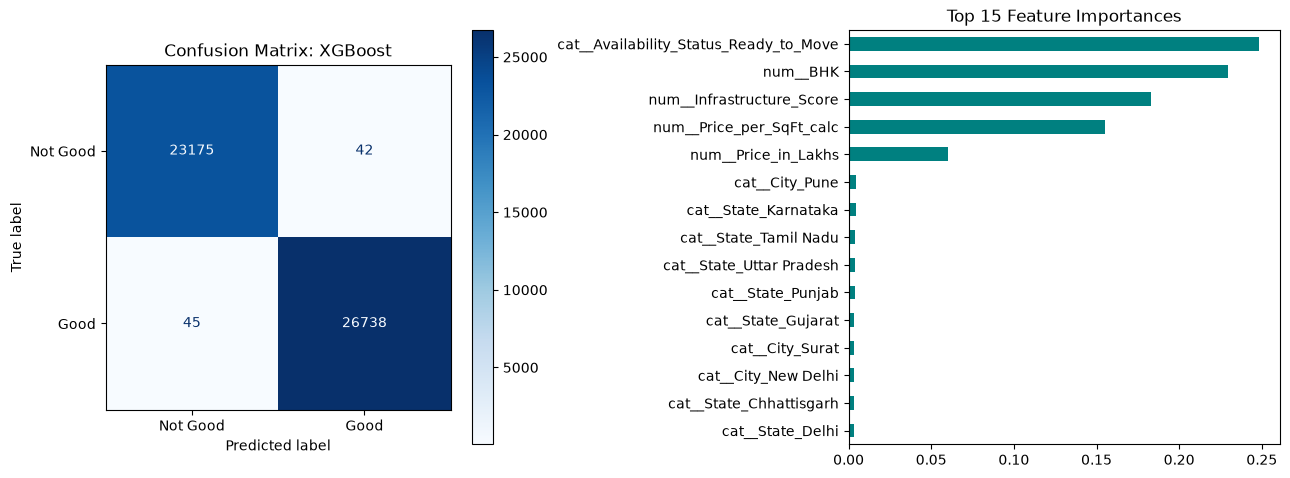

cat__Availability_Status_Ready_to_Move    0.248569
num__BHK                                  0.229352
num__Infrastructure_Score                 0.182797
num__Price_per_SqFt_calc                  0.155158
num__Price_in_Lakhs                       0.060421
cat__City_Pune                            0.004532
cat__State_Karnataka                      0.004270
cat__State_Tamil Nadu                     0.004106
cat__State_Uttar Pradesh                  0.003911
cat__State_Punjab                         0.003714
cat__State_Gujarat                        0.003569
cat__City_Surat                           0.003510
cat__City_New Delhi                       0.003481
cat__State_Chhattisgarh                   0.003432
cat__State_Delhi                          0.003343
dtype: float32

In [22]:
pred = best_pipe.predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Not Good", "Good"]).plot(ax=ax[0], cmap="Blues")
ax[0].set_title(f"Confusion Matrix: {best_key}")

model = best_pipe.named_steps["model"]
names = best_pipe.named_steps["prep"].get_feature_names_out()
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=names)
else:
    imp = pd.Series(np.abs(model.coef_[0]), index=names)
imp.nlargest(15).sort_values().plot(kind="barh", ax=ax[1], color="teal")
ax[1].set_title("Top 15 Feature Importances")
plt.tight_layout(); plt.show()

imp.nlargest(15)

In [24]:
done = [r["run_name"] for r in results]
for name in ["LogisticRegression", "RandomForest"]:
    run_name = f"clf_{name}_all_features"
    if run_name in done:
        print("skip", run_name); continue
    m, p = models[name]
    r, pipe = run_experiment(run_name, m, p, X_train, X_test, y_train, y_test, num_features, cat_features)
    results.append(r); pipes[name] = pipe

print(list(pipes.keys()))

skip clf_LogisticRegression_all_features
skip clf_RandomForest_all_features
['XGBoost', 'XGBoost_reduced', 'LogisticRegression', 'RandomForest']
